# IGVF meeting figures

Six figures, in talk order. Every panel is a call into `igvf_meeting_figures2_analysis`;
nothing in this notebook opens a data store, so re-running a cell is instant and editing
a colour or a label never costs a reload.

**If a panel raises about a missing cache file**, build it once:

```bash
sbatch run_igvf_meeting_figures2.slurm          # all three stages
sbatch run_igvf_meeting_figures2.slurm borzoi   # or just one
```

---

## Conventions

### Naming

Every arm has exactly one display name, defined once in `igvf_arms.py` and used by every
figure. The source notebooks disagreed with each other - the same checkpoint
(`nomlm_maskonly.npy`) was `cis-Mamba (GM12878 DNase logFC)` in the dsQTL panel and
`cis-Mamba (1 cell type)` in the eQTL panel. It is now `cis-Mamba (1 cell type)` everywhere,
and the assay lives in the axis label rather than in the arm name. **To rename an arm across
all six figures, edit its `label` in `igvf_arms.py` and re-run the cell** - no rebuild, because
the cache is keyed on a stable `id`, not on the label.

### Colour

One hue per family, shades within it. Darkest = the base or headline model of that family,
lighter = further from it.

| Family | Hue | Arms |
|---|---|---|
| cis-Mamba (this work) | **green** | 1 CT (Enformer grid), no pretraining, 8 CTs, 1 CT (Borzoi grid) |
| Enformer | **red** | pretrained, retrained 1/16/42 CTs |
| Borzoi | **blue** | pretrained, LoRA, full FT, from scratch |
| AlphaGenome | **gold** | - |
| ChromBPNet | **purple** | DNase/ATAC x logFC/IPS |
| references (nulls, measured assays) | **grey** | never a model |

The Enformer-grid and Borzoi-grid cis-Mamba arms share both the darkest green and the label
`cis-Mamba (1 cell type)` deliberately: they are the same method on two grids and never appear
in the same panel, so "our model" reads as one thing throughout the talk. They keep separate
cache keys, because they are separate checkpoints. Identity never rests on colour alone -
every bar carries an axis label and a printed value.

### Which arms can appear where

`igvf_arms.py` records, per arm, which benchmarks it is valid in, so a panel cannot silently
include an arm that has no scores there:

- **`cis-Mamba (no pretraining)` predicts expression only.** It exists on the Enformer CAGE
  grid and in the eQTL benchmark; there is no dsQTL arm for it, and none is implied by its
  absence.
- **There is no no-pretraining arm on the Borzoi grid either** - that grid has a single
  cis-Mamba arm, the epoch-4 run, and it carries the same label and colour as the
  Enformer-grid arm. The epoch-4 and epoch-10 runs were previously used interchangeably;
  only epoch 4 is shown now, everywhere.
- **AlphaGenome is not held out on the Borzoi fold3 grid.** Panels on that grid append
  *(not held out)* to its label automatically.
- **ChromBPNet is dsQTL-only.**
- **Two 1-cell-type retrained Enformers exist**, at 768 and 1536 channels. Only the 1536ch run
  is shown, labelled plainly `Enformer (retrained, 1 CT)`. The 768ch run is still scored, cached
  and gated -- it is flagged `hidden=True` in `igvf_arms.py`, which removes it from every panel
  without touching the cache. Deleting that flag brings it back with no rebuild.

### Metrics

`metric='sm'` (default) is smoothed-log Pearson - `log1p` then a Gaussian along the bin axis,
sigma=1.5 at 128 bp and sigma=6.0 at 32 bp so the two grids smooth over the same physical
distance. `metric='raw'` is plain Pearson. Both are cached; switching is a keyword.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import igvf_arms as A
import igvf_meeting_figures2_analysis as F

# Editing igvf_arms.py or the analysis module and re-running a figure cell picks the
# change up immediately -- no kernel restart, no reload of any data.
print('cache :', F.CACHE)
print('figs  :', F.FIGDIR)
for stage in ['enformer', 'borzoi', 'qtl']:
    done = F.CACHE / f'{stage}.done.json'
    print(f'  {stage:9s}',
          'built ' + json.loads(done.read_text())['built'] if done.exists()
          else 'NOT BUILT -- sbatch run_igvf_meeting_figures2.slurm ' + stage)

cache : /data1/lesliec/sarthak/caduceus/code_test/IGVF_meeting_figures2_cache
figs  : /data1/lesliec/sarthak/caduceus/code_test/igvf_meeting_figs2
  enformer  built 2026-09-09 10:30:45
  borzoi    built 2026-09-09 10:41:45
  qtl       built 2026-09-09 10:33:42


---
## 1 - The example locus

`comparing_model5` section 9c rank 9 - region 3304, minus strand, chr8. Pretrained Borzoi and
AlphaGenome only, then the truth, then the cross-cell-type average, then the genes.

Read it as a build: the two models agree with **each other**, and then the average shows what
they were actually agreeing with. Both put their one large spike at ~40.900 Mb, which is where
the cross-cell-type average peaks -- while the observed CAGE peaks at ~40.925 and ~40.947, where
neither model puts anything. AlphaGenome is on its own axis because it predicts in its own units
rather than Borzoi squashed counts, and it is flagged *(not held out)*.

Observed GM12878 DNase sits below the truth axis next to the gene models: a different assay in
different units, so it is not read as another prediction. The gene track is every GENCODE
biotype, which already contains the protein-coding genes.

This locus is rank 9 of a ranked gain list, so it is selected for illustration -
figure 2 carries the distribution.

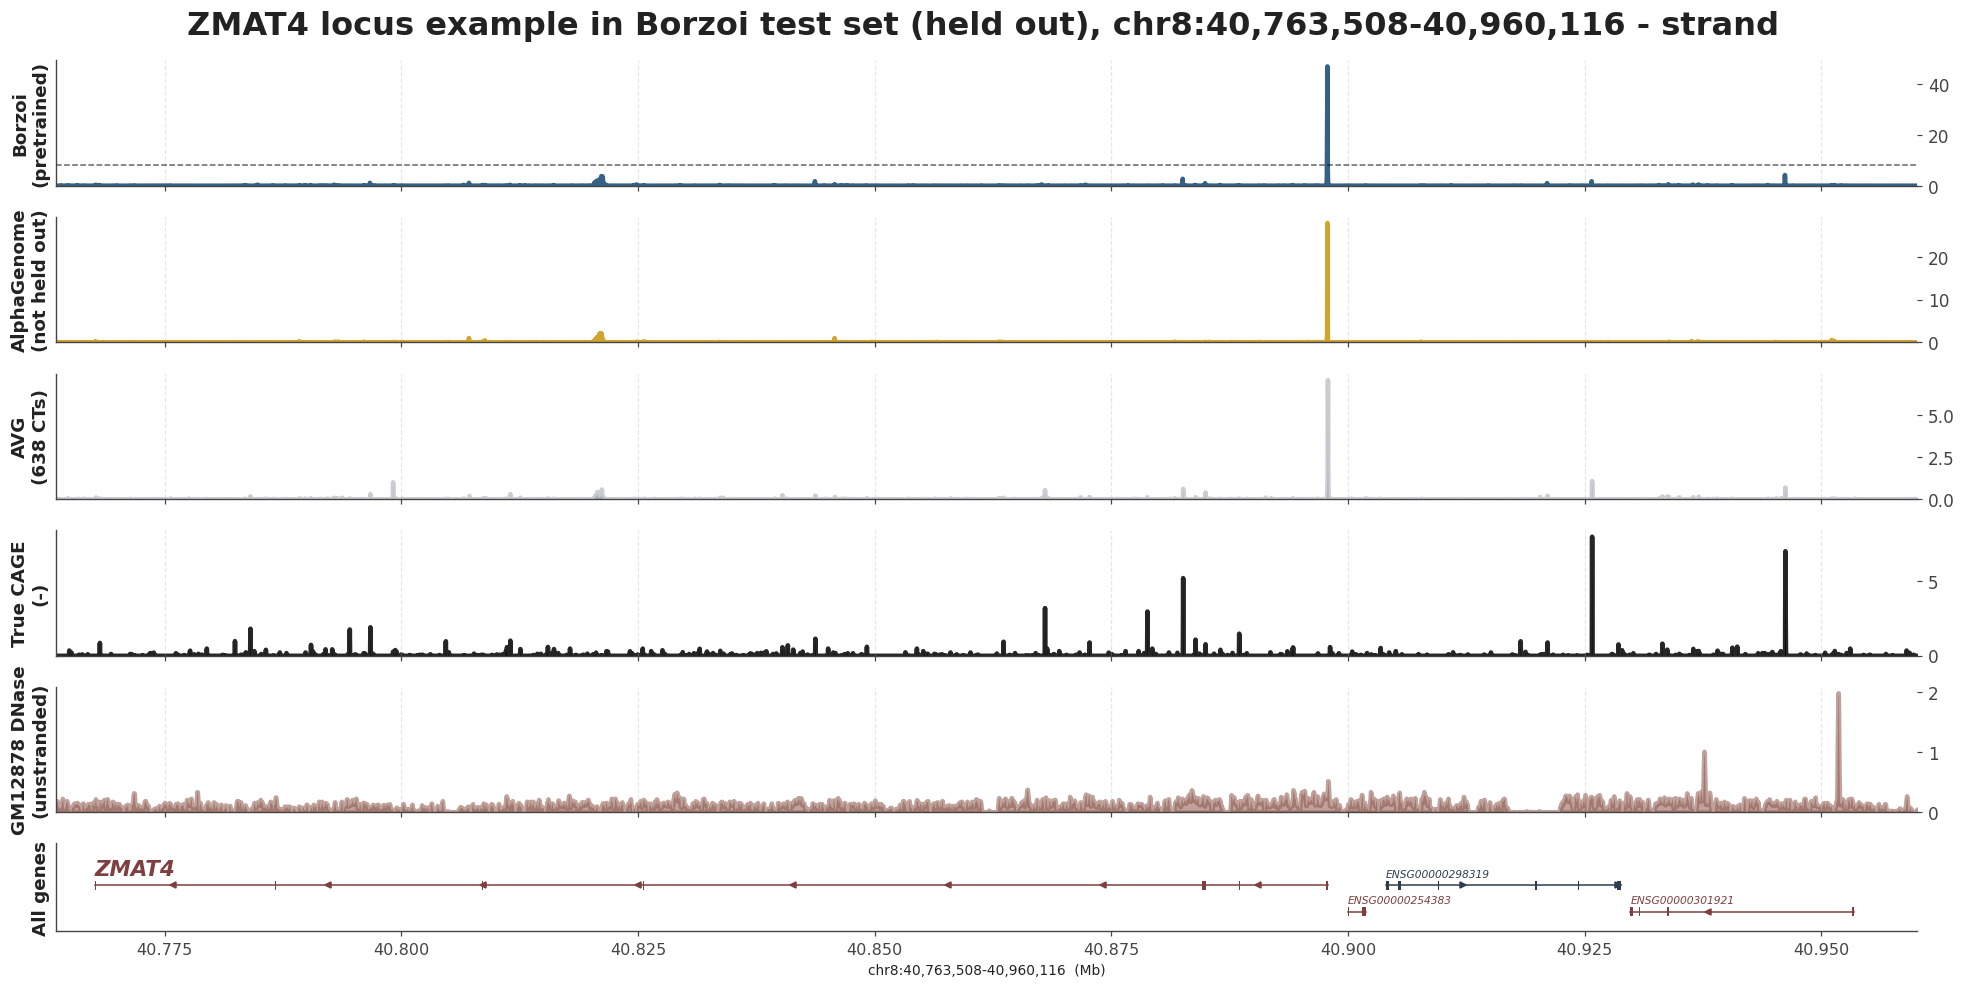

In [2]:
fig = F.panel1_locus()

# Every arm is in the cache, so the retrained models are a keyword away:
#   F.panel1_locus(arms=('borzoi_pre', 'alphagenome', 'borzoi_trunk',
#                        'borzoi_scratch', 'mamba_1ct_borzoi'))
# show_dnase=False drops the observed DNase track; gene_tracks='both' adds a
# separate protein-coding + IG/TR track above the all-biotype one.

---
## 1b - The same locus, adapted models

Figure 1 again -- same region, same axes, same truth and same cross-cell-type average -- with
the finetuned and from-scratch Borzoi arms and cis-Mamba in place of the stock models.

Read as a pair with figure 1, this is the before and after on one picture. Pretrained Borzoi and
AlphaGenome are deliberately absent: figure 1 already showed them, and leaving them in would
make the audience re-find them rather than see what changed.

Placed here so the two locus panels sit together while you work. The poster order puts this
later; moving it is a cell drag, and nothing else depends on its position.

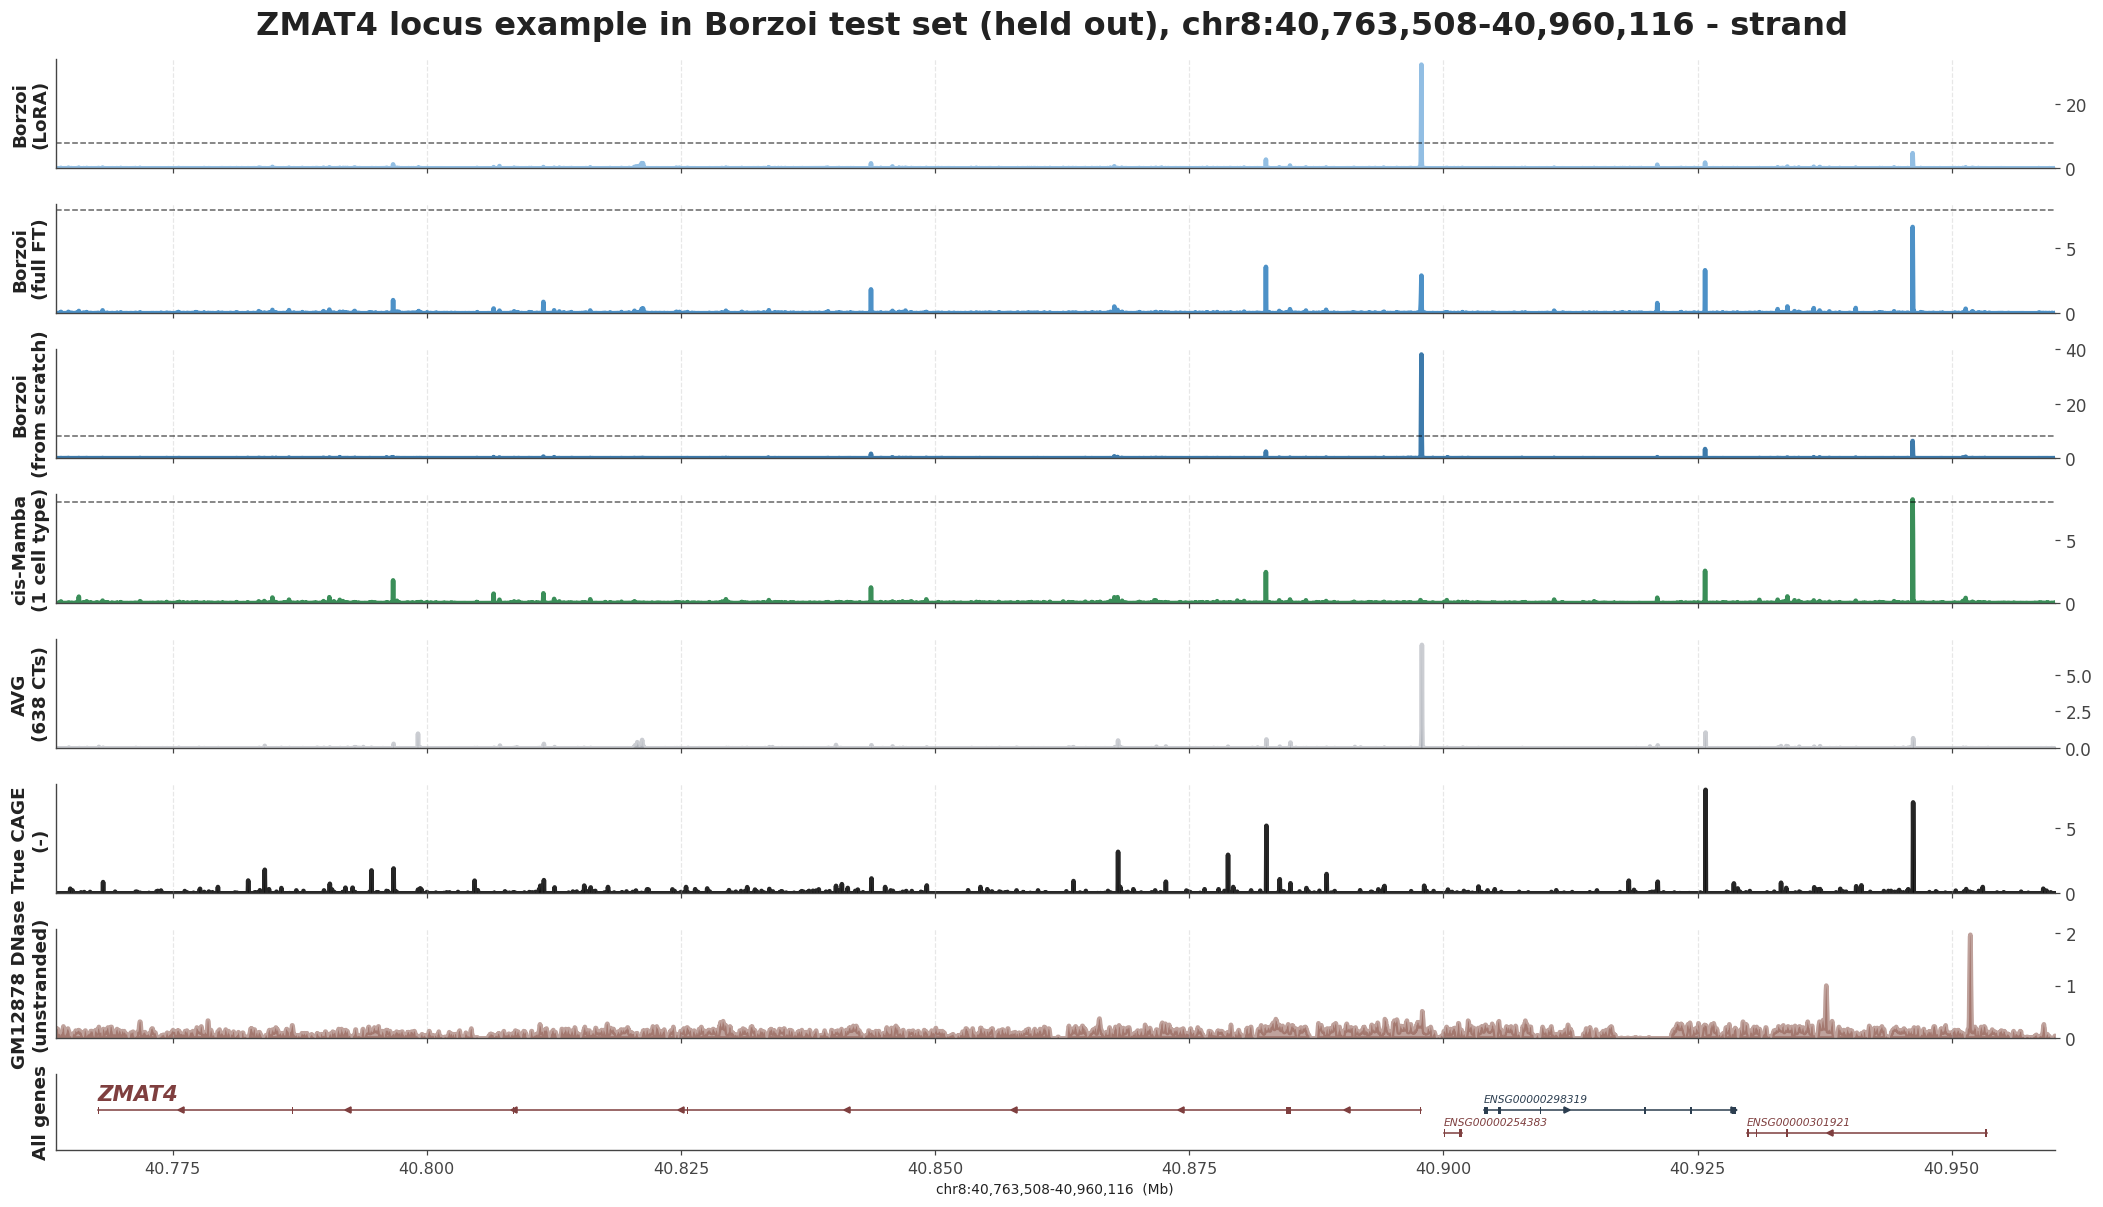

In [3]:
fig = F.panel1b_locus_retrained()

# Add stock Borzoi back for a direct in-panel contrast:
#   F.panel1b_locus_retrained(arms=('borzoi_pre',) + F.FIG1B_ARMS)

---
## 2 - Per-region accuracy, the premise

By the metric the field reports, everything looks fine. This is the claim the rest of the talk
undermines, so it goes first.

AlphaGenome is excluded from both panels. The no-pretraining ablation appears on the Enformer
grid, which is the only grid it exists on - introduce the two phases here and the ablation
answers itself on the same slide.

Ranked bars rather than boxplots, in the same style as figure 6 - the boxes were using a lot of
space to say little. The bar is the mean per-region correlation, the number the boxplots printed
anyway. `show_spread=True` adds the interquartile range back if you want it.

Worth knowing rather than reading off the bars: on the Borzoi grid the best-to-worst gap in
means is **0.054**, against a median within-arm IQR of **0.296**. Per-region spread dwarfs the
between-arm differences by more than five to one. That is the premise this figure exists to
establish - on the metric the field reports, these arms are not meaningfully separated.

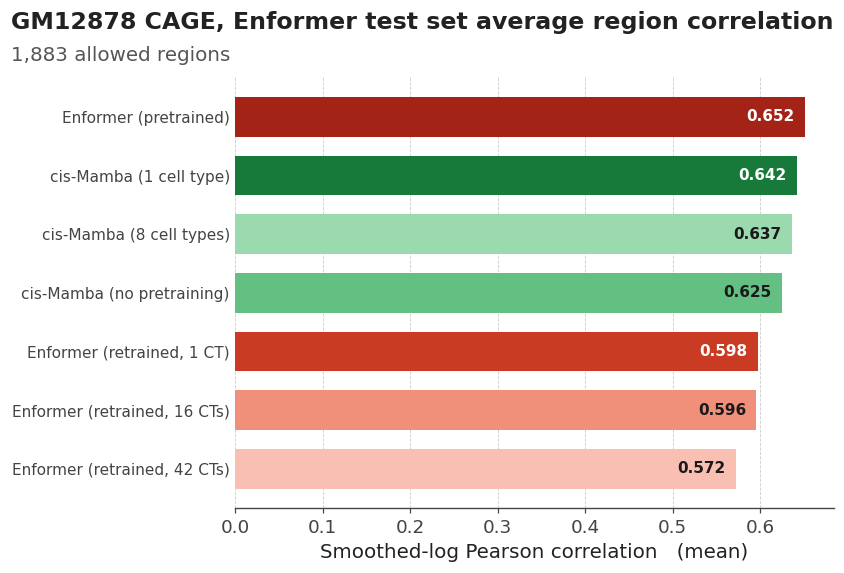

In [4]:
fig = F.panel2a_accuracy_enformer()

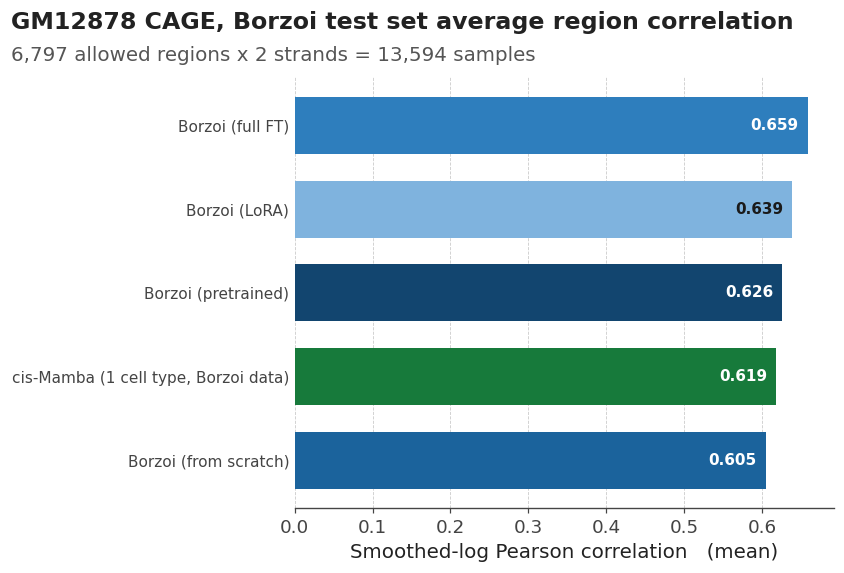

In [5]:
fig = F.panel2b_accuracy_borzoi()

---
## 3 - The stratum ladder, the turn

Same metric, same arms, same bootstrap. Only the stratum changes, and each rung is a strict
subset of the one to its left. The null falling to 0 is what tells you the last panel measures
reliance on the generic shortcut rather than task difficulty.

**3a** is a schematic on invented data showing what each rung selects; **3b** and **3c** are the
real ladders on the two grids. The schematic carries no counts, thresholds or formulae - it is
built to be narrated. It applies the same *shape* of rule the pipeline does, so it cannot drift
from what it claims to explain, and it is not cached: it draws in well under a second.

`F.panel3a_detail()` is a second, fully annotated version of the same thing - per-bin class
strips, printed criteria, pos/neg counts at every rung. Too busy for a slide, useful as a
reference while writing the talk.

One drawing choice worth knowing. **Class is a strip under the axis, not a fill under the
curve.** Filling the curve fought with the average and accessibility lines drawn over it, and it
forced a choice between two bad options: band by value and the base of every tall peak turns
red, or band by class and there is a hole under every peak. The strip has neither problem -
every position gets equal area whatever its value, and the curves above stay readable, which is
what makes the true-vs-average contrast in R2 legible at all.

Four things that are easy to state wrongly when narrating it:

- **R0 is not a binary split of every bin.** Positives are `observed >= 1.0`, negatives are
  `observed < 0.2`, and the bins in between are in *neither* class.
- **R1 restricts both classes**, not just the positives, and it is within 500 bp of a
  protein-coding **TSS** - not anywhere in a gene body.
- **R2 is not "average is zero".** Positives need the cross-CT average in the *bottom half* of
  promoter bins; negatives need it in the *top decile*. The two cuts are asymmetric.
- **R3 applies to both classes in opposite directions.** A positive must be ATAC-open
  (`>= p95`), a negative must be ATAC-closed. And the bin *is* the accessible site, rather than
  being near one.

The measured-accessibility row is hatched at R3: it *defines* those classes, so 1.000 there
restates the definition and is not a result.

The dashed 0.5 guide appears on rungs 0-1 only. Those are ordinary discrimination, where 0.5 is
chance. Rungs 2-3 are scaled between *pure average* and *fully specific*, so 0.5 has no direct
reading there and is neither drawn nor labelled.

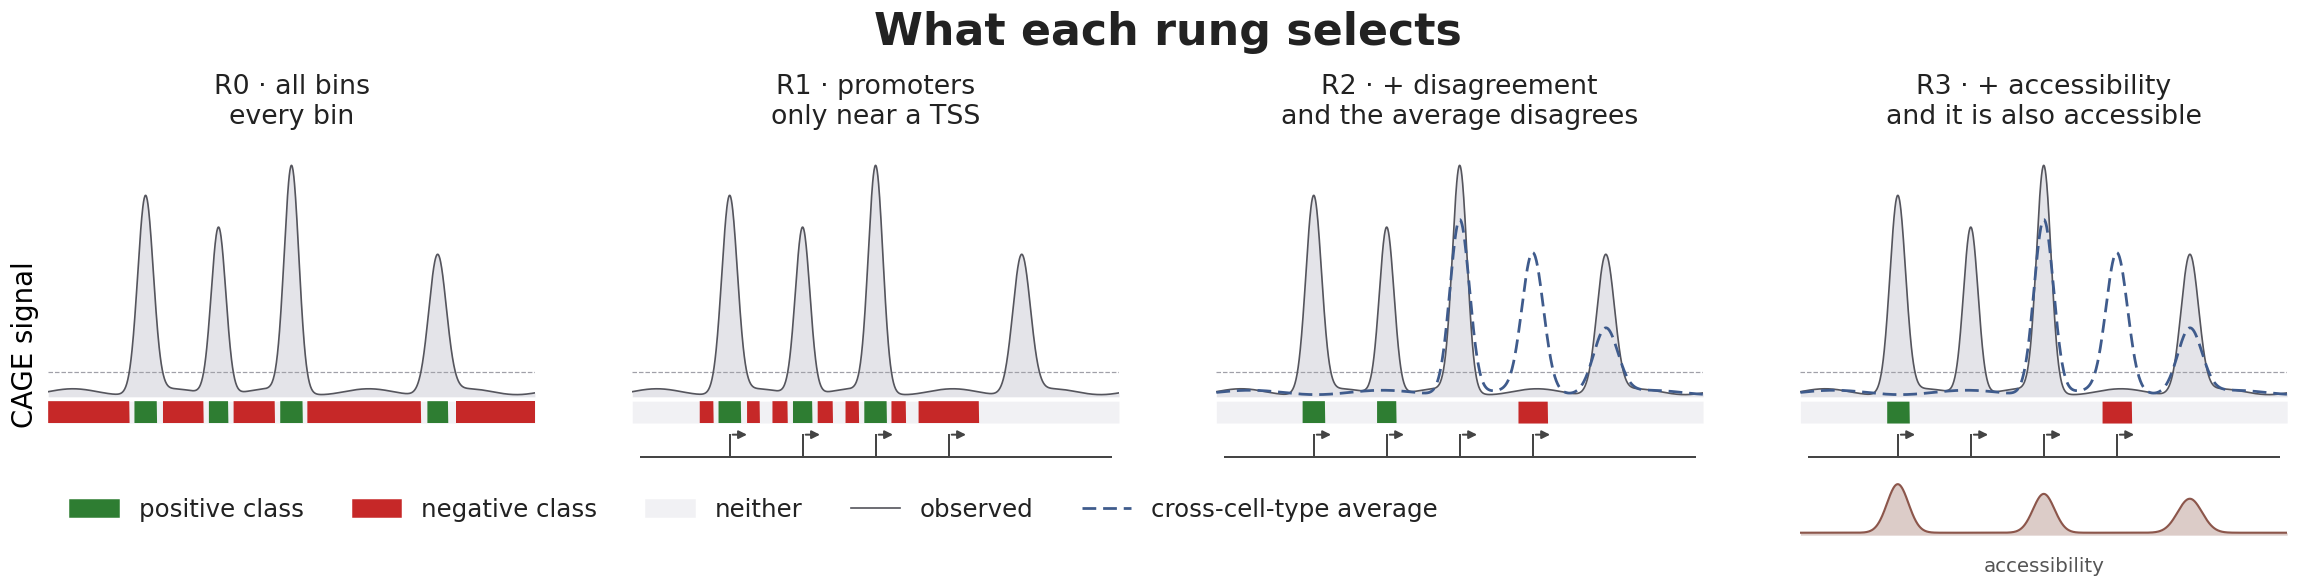

In [6]:
fig = F.panel3a_schematic()

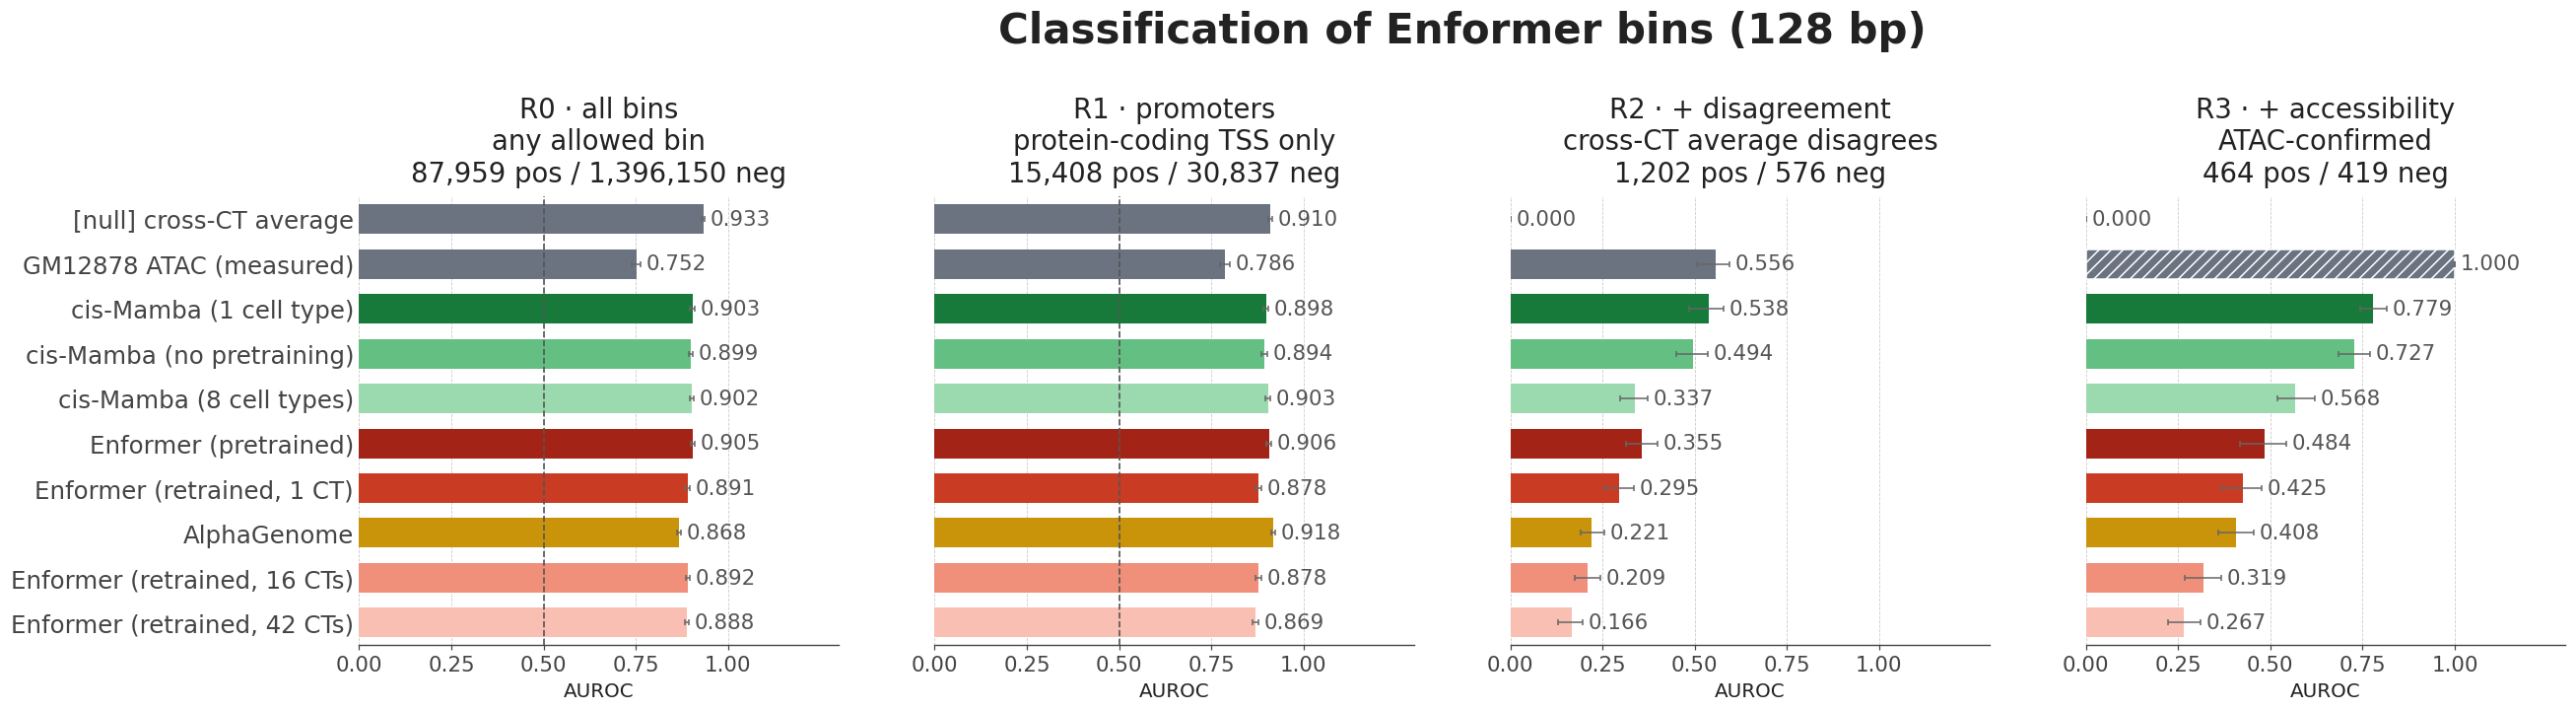

In [7]:
fig = F.panel3b_ladder_enformer()

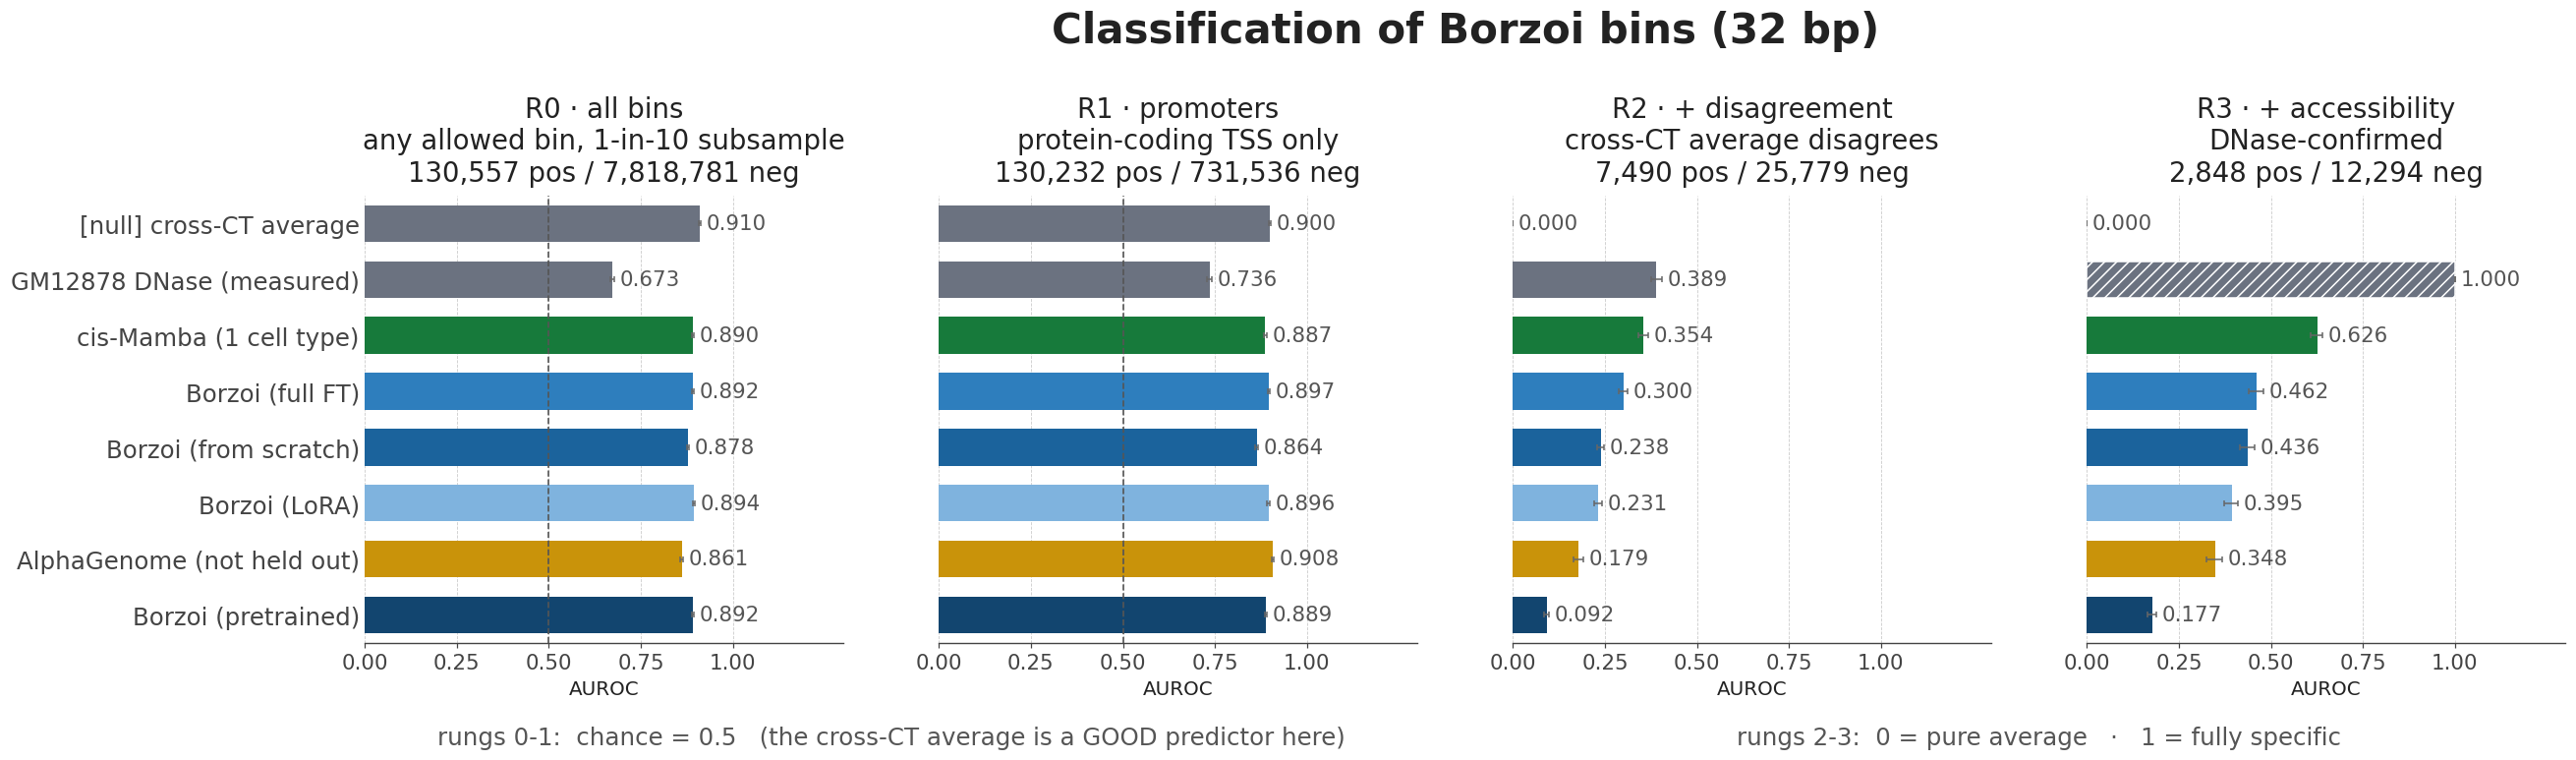

In [8]:
fig = F.panel3c_ladder_borzoi()

---
## 3 combined - 3a, 3b and 3c on one slide

All three stacked into a single tall panel, for when the talk wants the whole ladder story --
schematic, then both real grids -- on one slide instead of three. Each sub-panel is rendered
through its own function exactly as it is on its own (`panel3a_schematic`,
`panel3b_ladder_enformer`, `panel3c_ladder_borzoi`) and then composited as images, stacked top to
bottom at a shared width -- there is no shared x- or y-axis across a schematic and two bar-chart
grids for a redraw to align, so none is attempted.

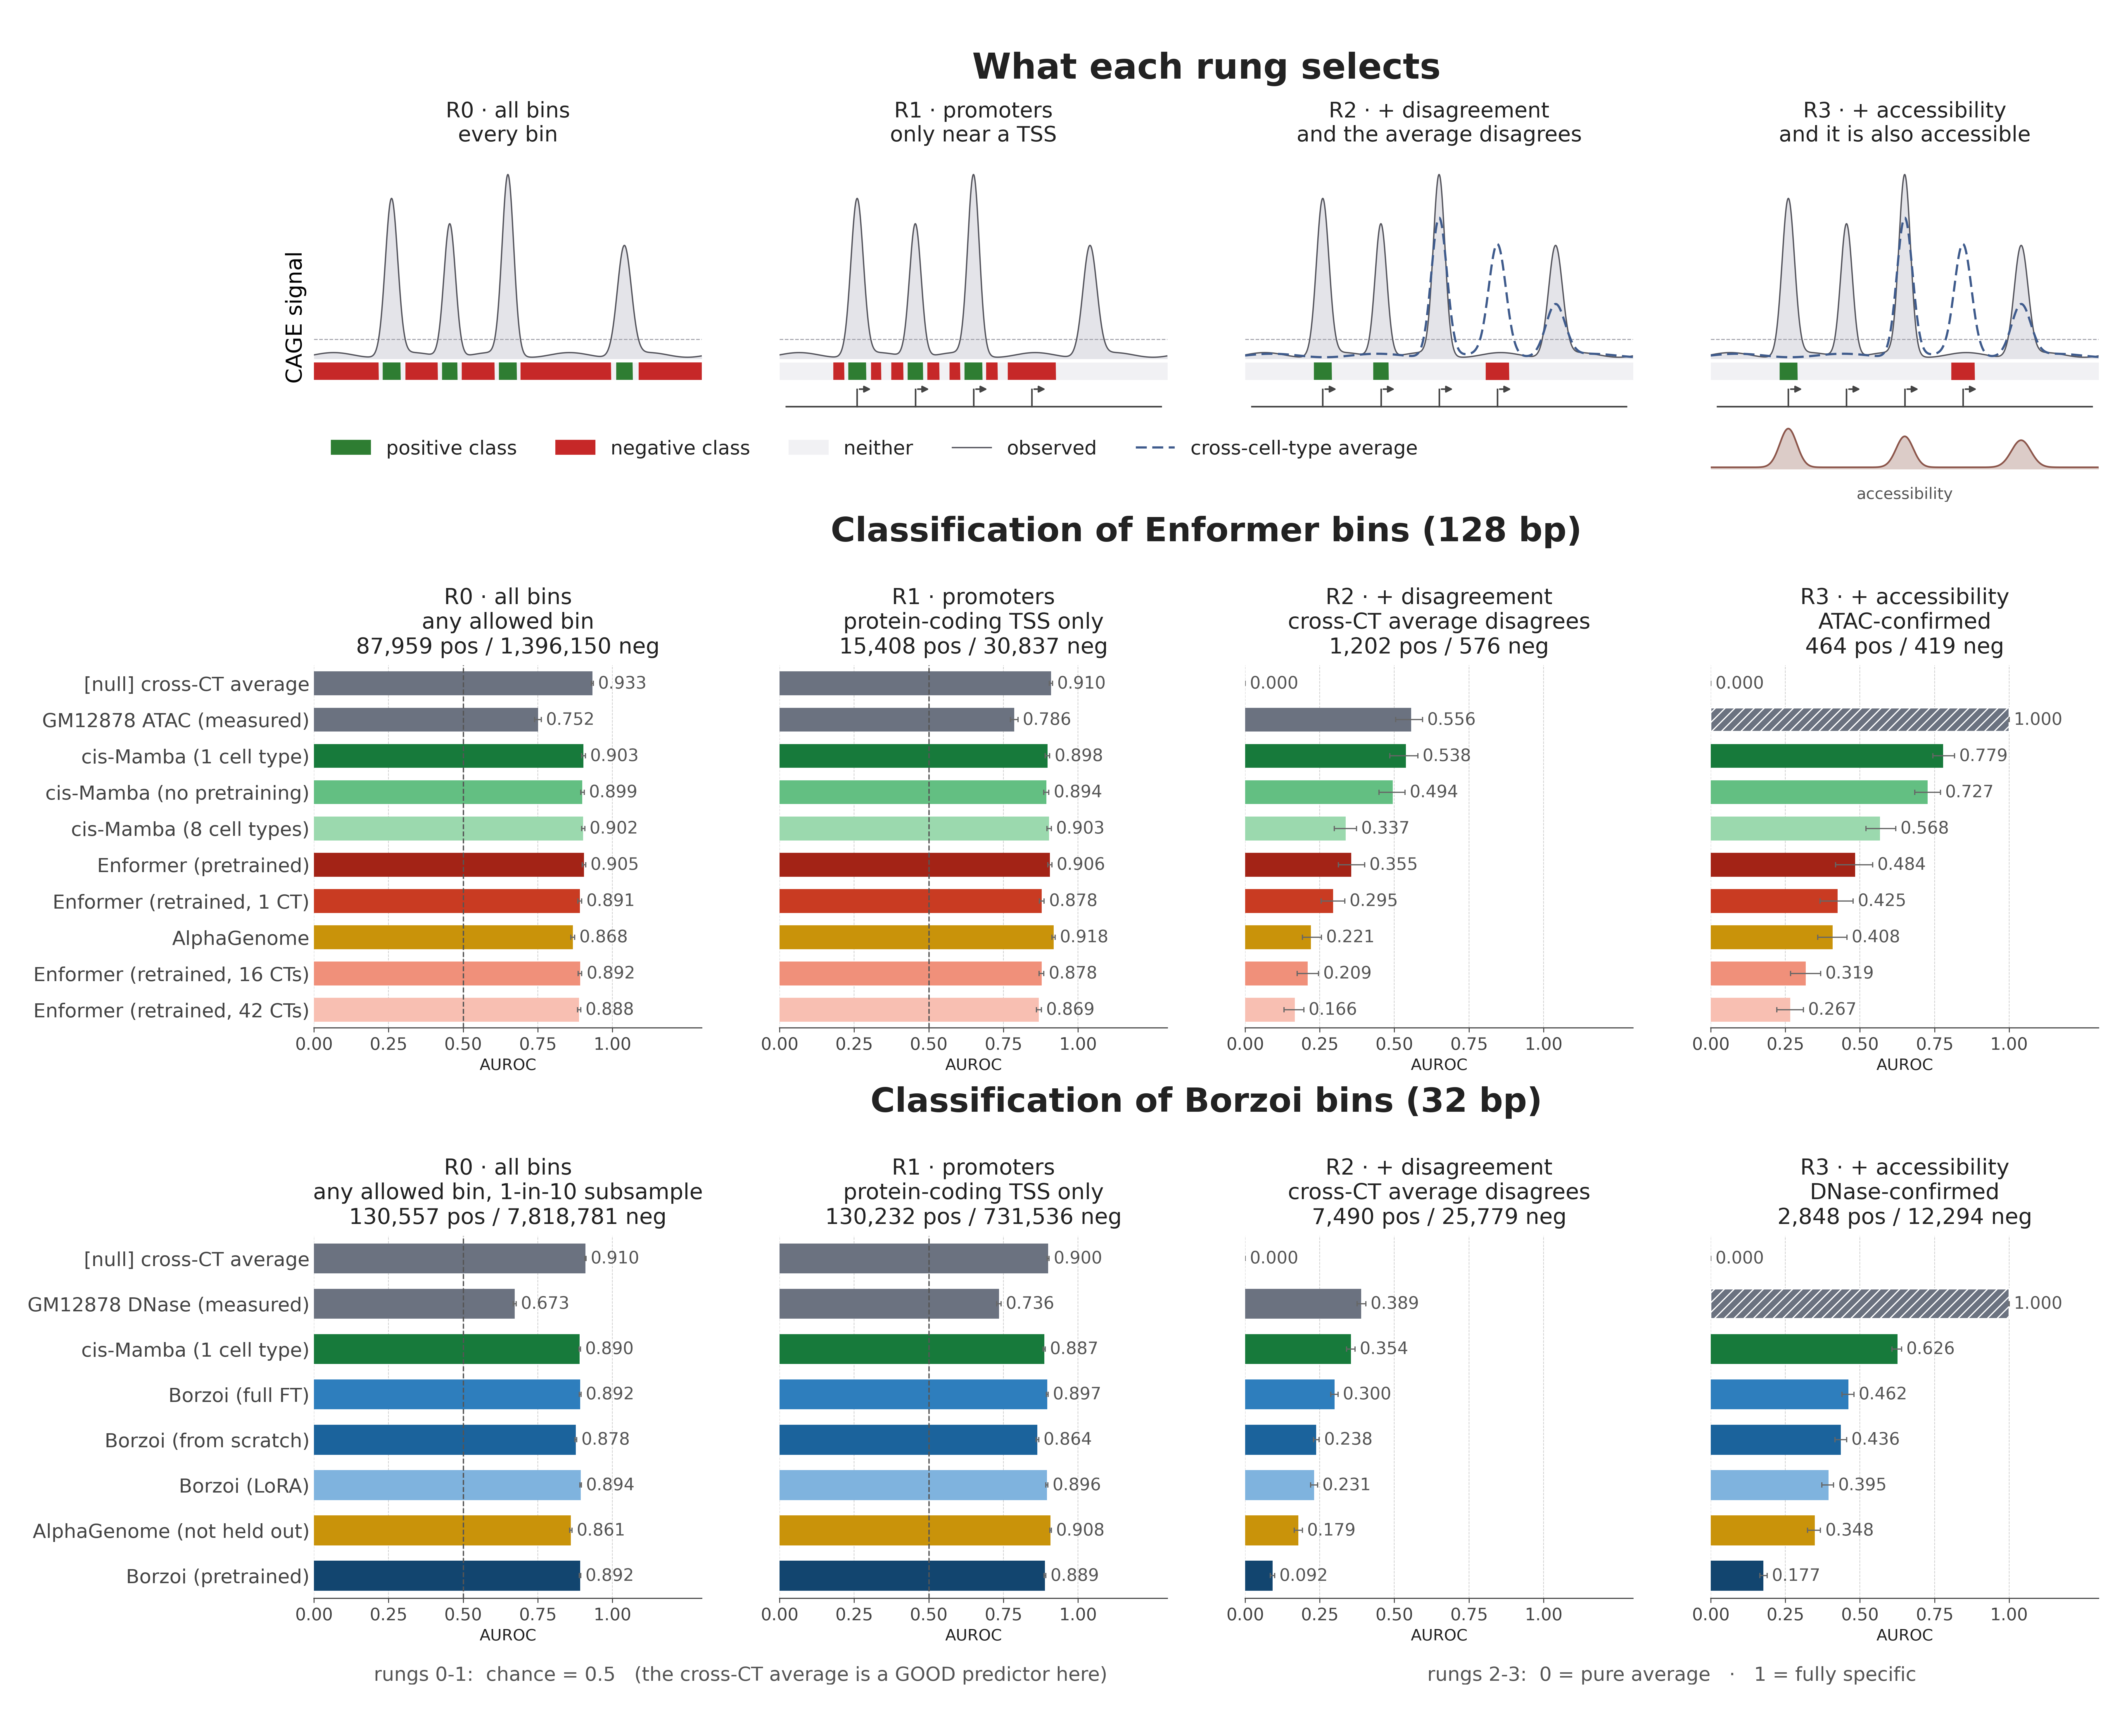

In [9]:
fig = F.panel3_combined()

---
## 4 - Accuracy vs how generic the region is

`comparing_model4` section 13, reduced to running medians - the ringed marker region and the
background scatter are both dropped. x rising means the region's GM12878 signal looks more
like the average of every other cell type.

Pass `scatter=True` to bring the faint points back.

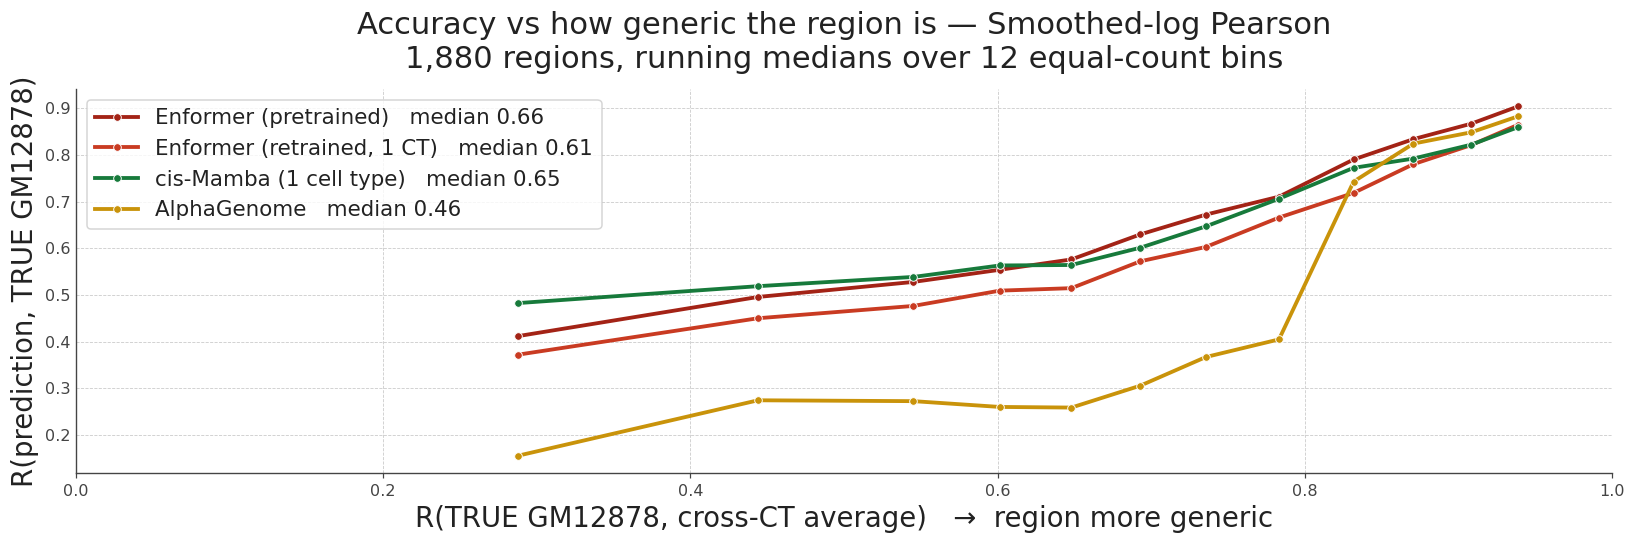

In [10]:
fig = F.panel4_generic()

---
## 5 - dsQTL by peak specificity

The same stratification applied to variant effects instead of track reconstruction: identical
variants and identical metric, split by whether the peak is broad (generic) or narrow
(cell-type specific).

The table comes straight from `dsQTL_benchmark8`; this only recolours and relabels it.

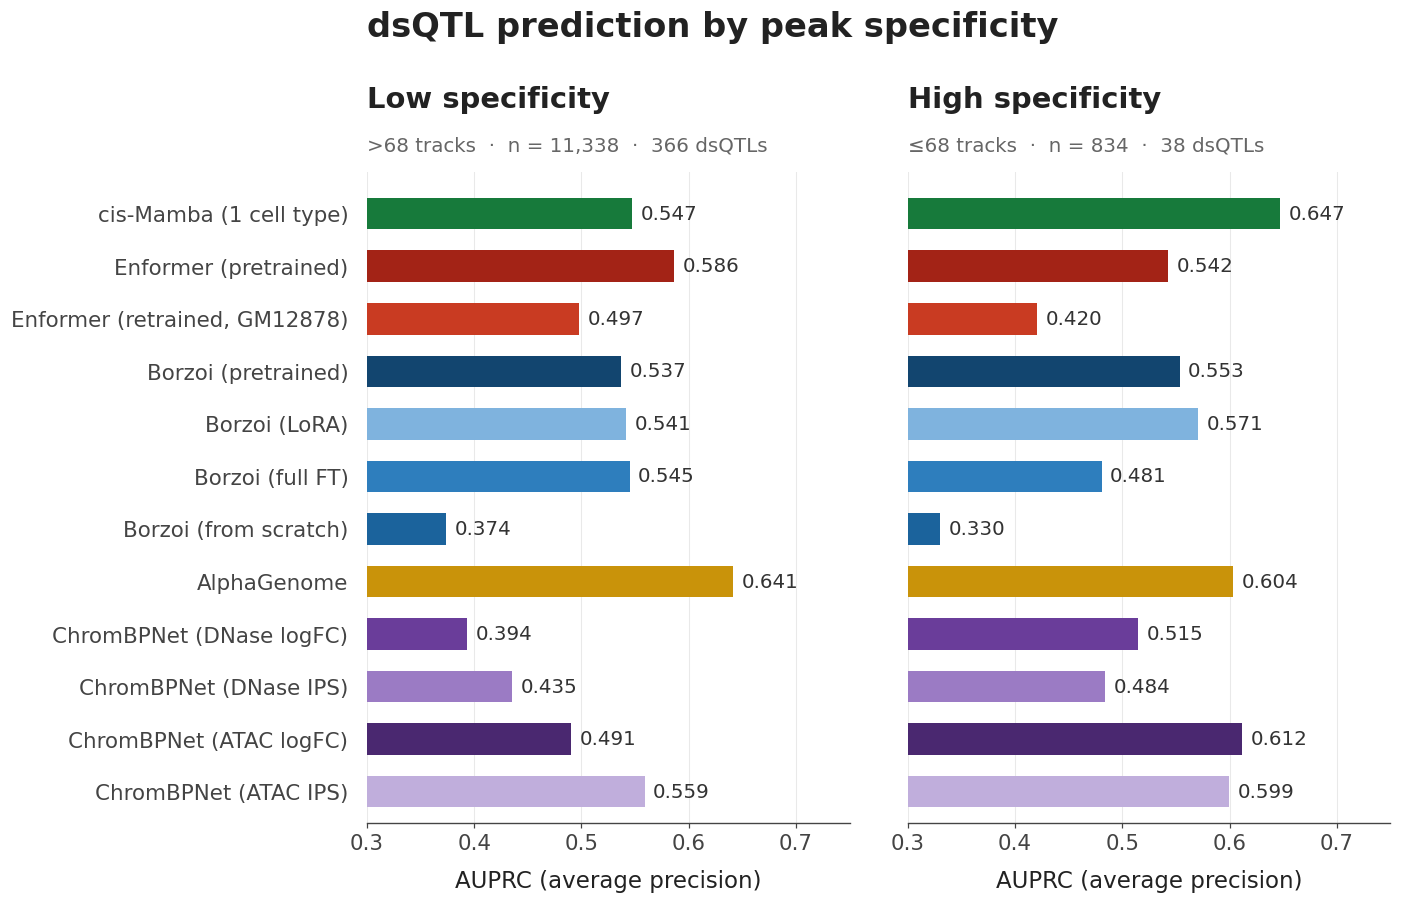

In [11]:
fig = F.panel5_dsqtl('merged')
# F.panel5_dsqtl('bins')   # the 128-bp-bin definition

---
## 6 - LCL eQTL by distance to TSS

Accessibility is held fixed between ref and alt, so whatever separates the arms is the sequence
channel. The distal facet is the one that carries the specificity argument - land it as the
escalation, not as a third instance of the same pattern.

`cis-Mamba (no pretraining)` is on this panel: it is the second and last place the pretraining
ablation appears.

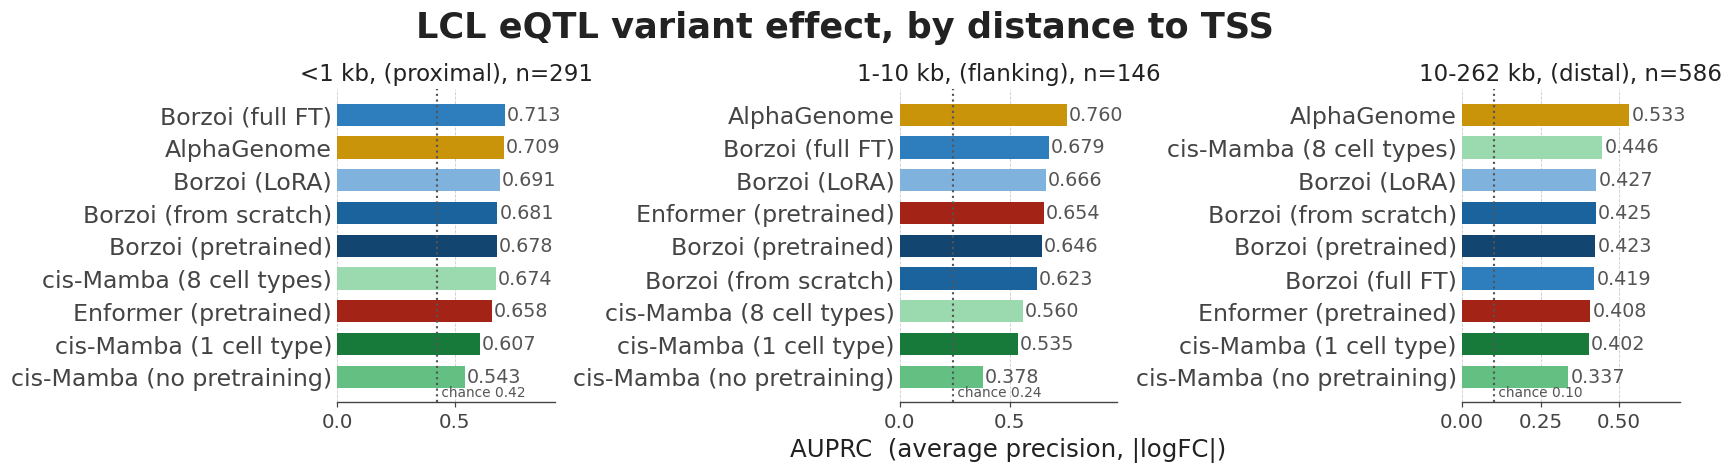

In [12]:
fig = F.panel6_eqtl()

---
## Rebuilding

The cache is the only thing standing between a figure and a multi-minute reload, so it is worth
knowing what invalidates it.

Figure 3a needs no stage at all - it is a schematic on invented numbers.

| Stage | Reads | Feeds |
|---|---|---|
| `enformer` | GM12878 CAGE target, 9 prediction arrays, labels.zarr, ATAC | 2a, 3b, 4 |
| `borzoi` | `GM12878CAGE.zarr`, 6 prediction arrays, DNase npz | 1, 1b, 2b, 3c |
| `qtl` | eQTL ref/alt arrays; `dsQTL_benchmark8_cache/stratified_metrics.tsv` | 5, 6 |

Only a change to a **source prediction array** requires a rebuild. Renaming an arm, recolouring
a family, changing which arms a panel shows, switching metric, or restyling anything does not -
those are `igvf_arms.py` or analysis-module edits, and `%autoreload 2` picks them up on the next
cell run.

Both grid stages assert against the numbers `comparing_model4` section 20/20b and
`comparing_model5` section 12/12b published, to 0.002, so a silently changed input fails the
build rather than quietly moving a figure.